# CLIP-DR Inference on APTOS & DeepDRiD

This notebook evaluates the official `CLIP-DR` checkpoints on the APTOS and DeepDRiD datasets.
We use the pre-trained checkpoints `APTOS.ckpt` and `DEEPDR.ckpt` from the cloned `CLIP-DR` repository.

In [1]:
import os, sys
import pandas as pd
from pathlib import Path
from tqdm import tqdm

import torch
import pytorch_lightning as pl
from omegaconf import OmegaConf
from pytorch_lightning.callbacks import TQDMProgressBar

# ── Locate Project Root ───────────────────────────────────────────────
ROOT = Path.cwd()
while not (ROOT / 'configs').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# ── Add CLIP-DR to Path ───────────────────────────────────────────────
CLIP_DR_PATH = ROOT / "CLIP-DR"
sys.path.insert(0, str(CLIP_DR_PATH))

from clipdr.runnerr.runner_test import Runner
from clipdr.runnerr.data import RegressionDataModule

## 1. Prepare Data Formats for CLIP-DR

The `CLIP-DR` dataset module expects `.txt` files containing `image_path label`.
We will convert the `CFP_manifest.csv` files for APTOS and DeepDRiD into this format.

In [2]:
import sys
sys.path.insert(0, os.path.abspath("."))
from src.data.paths import resolve_image_root

def create_clipdr_txt(manifest_path, output_txt):
    """Write `<absolute image path> <grade>` lines (CLIP-DR format) for the test split.

    Manifest paths are relative to the dataset root in src/data/paths.py, so the
    list is rebuilt for whichever machine runs this notebook.
    """
    df = pd.read_csv(manifest_path)
    root = resolve_image_root(manifest_path)
    # We only test, so we can take the whole dataset or just the test split.
    # Here we take the 'test' split if available, otherwise 'val', otherwise everything.
    if 'test' in df['split'].unique():
        test_df = df[df['split'] == 'test']
    elif 'val' in df['split'].unique():
        test_df = df[df['split'] == 'val']
    else:
        test_df = df

    with open(output_txt, 'w') as f:
        for _, row in test_df.iterrows():
            img_path = row['path']
            if root is not None and not os.path.isabs(img_path):
                img_path = os.path.join(str(root), img_path)
            if not os.path.exists(img_path):
                raise FileNotFoundError(img_path)
            f.write(f"{img_path} {int(row['grade'])}\n")
    print(f"Saved {len(test_df)} samples to {output_txt}")

os.makedirs("data/CLIPDR_splits", exist_ok=True)

APTOS_TEST_TXT = "data/CLIPDR_splits/aptos_test.txt"
create_clipdr_txt("data/APTOS/CFP_manifest.csv", APTOS_TEST_TXT)

DEEPDR_TEST_TXT = "data/CLIPDR_splits/deepdrid_test.txt"
create_clipdr_txt("data/DeepDRiD/CFP_manifest.csv", DEEPDR_TEST_TXT)

Saved 366 samples to data/CLIPDR_splits/aptos_test.txt
Saved 400 samples to data/CLIPDR_splits/deepdrid_test.txt


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import torch.nn.functional as F
import torch

def plot_model_analysis(model, datamodule, dataset_name):
    print(f"--- Analyzing {dataset_name} ---")
    datamodule.setup('test')
    loader = datamodule.test_dataloader()
    
    model.eval()
    if torch.cuda.is_available():
        model.cuda()
    
    all_preds, all_targets = [], []
    sample_imgs, sample_labels, sample_preds = None, None, None
    sample_img_f, sample_txt_f = None, None
    
    with torch.no_grad():
        for i, batch in enumerate(loader):
            imgs, labels = batch[0], batch[1]
            if torch.cuda.is_available():
                imgs = imgs.cuda()
                labels = labels.cuda()
                
            our_logits, img_f, txt_f = model.module(imgs)
            preds = our_logits.argmax(dim=-1)
            
            all_preds.append(preds.cpu())
            all_targets.append(labels.cpu())
            
            if i == 0:
                sample_imgs = imgs.cpu()
                sample_labels = labels.cpu()
                sample_preds = preds.cpu()
                sample_img_f = img_f.cpu()
                sample_txt_f = txt_f.cpu()
                
    targets = torch.cat(all_targets).numpy()
    preds = torch.cat(all_preds).numpy()
    
    # 1. Confusion Matrix
    cm_counts = confusion_matrix(targets, preds)
    cm_norm = cm_counts.astype(float) / (cm_counts.sum(axis=1, keepdims=True) + 1e-8)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    num_classes = cm_counts.shape[0]
    display_labels = [f'G{idx}' for idx in range(num_classes)]
    
    disp = ConfusionMatrixDisplay(cm_counts, display_labels=display_labels)
    disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f'Confusion Matrix (counts) - {dataset_name}', fontweight='bold')
    
    disp2 = ConfusionMatrixDisplay(np.round(cm_norm, 2), display_labels=display_labels)
    disp2.plot(ax=axes[1], cmap='Purples', colorbar=False)
    axes[1].set_title(f'Confusion Matrix (norm) - {dataset_name}', fontweight='bold')
    plt.show()
    
    # 2. Similarity Matrix Plots
    txt_sim = (sample_txt_f @ sample_txt_f.T).numpy()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    sns.heatmap(txt_sim, annot=True, cmap='coolwarm', ax=axes[0],
                xticklabels=display_labels, yticklabels=display_labels)
    axes[0].set_title("Text-Text Cosine Similarity")
    
    num_samples = min(10, len(sample_imgs))
    img_txt_sim = (sample_img_f[:num_samples] @ sample_txt_f.T).numpy()
    sns.heatmap(img_txt_sim, annot=True, cmap='viridis', ax=axes[1],
                xticklabels=display_labels, yticklabels=[f'Img {idx} (True: G{sample_labels[idx].item()})' for idx in range(num_samples)])
    axes[1].set_title("Image-Text Cosine Similarity")
    plt.show()
    
    # SMS Plot
    if getattr(model.module, 'sms', None) is not None:
        sms_module = model.module.sms
        mu_raw = sms_module.mu_raw.cpu().numpy()
        mu_smooth = sms_module.mu_smooth.cpu().numpy()
        shift = mu_smooth - mu_raw
        
        fig, ax = plt.subplots(figsize=(6, 4))
        ranks = np.arange(len(mu_raw))
        ax.plot(ranks, mu_raw, marker='o', label='Raw Mean', color='blue')
        ax.plot(ranks, mu_smooth, marker='s', label='Smoothed Mean', color='green')
        ax.bar(ranks, shift, alpha=0.3, label='Shift Applied', color='gray')
        ax.set_title(f'SMS Calibration - {dataset_name}')
        ax.set_xlabel('Rank')
        ax.set_ylabel('Similarity Mean')
        ax.set_xticks(ranks)
        ax.legend()
        plt.show()
        
    # 3. Qualitative Plot
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    
    for idx in range(num_samples):
        img = sample_imgs[idx] * std + mean
        img = img.permute(1, 2, 0).clamp(0, 1).numpy()
        axes[idx].imshow(img)
        diff = abs(sample_labels[idx].item() - sample_preds[idx].item())
        if diff == 0:
            title_color = 'green'
        elif diff == 1:
            title_color = '#DAA520' # Goldenrod (darker yellow for readability)
        else:
            title_color = 'red'
        axes[idx].set_title(f"True: G{sample_labels[idx].item()} | Pred: G{sample_preds[idx].item()}", color=title_color)
        axes[idx].axis('off')
    for idx in range(num_samples, len(axes)):
        axes[idx].axis('off')
    plt.suptitle(f"Qualitative Results - {dataset_name}", fontweight='bold')
    plt.tight_layout()
    plt.show()

## 2. Evaluate APTOS Checkpoint

In [3]:
# Load default CLIP-DR config
cfg = OmegaConf.load(str(CLIP_DR_PATH / "default.yaml"))

# Overwrite data paths for APTOS
cfg.data_cfg.test_images_root = ""  # Absolute paths are in the txt
cfg.data_cfg.train_dataloder_cfg.num_workers = 0
cfg.data_cfg.eval_dataloder_cfg.num_workers = 0

cfg.data_cfg.test_data_file = APTOS_TEST_TXT
cfg.data_cfg.val_data_file = APTOS_TEST_TXT
cfg.data_cfg.train_data_file = APTOS_TEST_TXT
cfg.data_cfg.train_images_root = ""
cfg.data_cfg.val_images_root = ""

# Setup runner checkpoint
aptos_ckpt = str(CLIP_DR_PATH / "APTOS.ckpt")
runner_cfg = cfg.runner_cfg
for k in runner_cfg.load_weights_cfg.keys():
    runner_cfg.load_weights_cfg[k] = None
runner_cfg.ckpt_path = aptos_ckpt

# Initialize Model and Data
aptos_model = Runner.load_from_checkpoint(aptos_ckpt, **OmegaConf.to_container(runner_cfg))
aptos_data = RegressionDataModule(**OmegaConf.to_container(cfg.data_cfg))

trainer = pl.Trainer(
    accelerator='auto', devices=1, 
    logger=False, 
    callbacks=[TQDMProgressBar(refresh_rate=1)]
)

Lightning automatically upgraded your loaded checkpoint from v1.9.4 to v2.6.5. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\CLIP-DR\APTOS.ckpt`
2026-08-09 12:36:30,096 - clipdr.utils.registry - INFO - Build obj: CLIPDR
2026-08-09 12:36:30,098 - clipdr.models.CLIPDR - INFO - Building CLIP model...
2026-08-09 12:36:30,099 - clipdr.models.CLIPDR - INFO - Text backbone : RN50's counterpart.
2026-08-09 12:36:32,645 - clipdr.models.CLIPDR - INFO - Image backbone: RN50
2026-08-09 12:36:32,647 - clipdr.models.CLIPDR - INFO - CLIP Image encoder: RN50!
2026-08-09 12:36:32,823 - clipdr.models.CLIPDR - INFO - convert `clip_model` to float32. if need fp16 model, call `clip.model.convert_weights`
2026-08-09 12:36:32,826 - clipdr.utils.registry - INFO - Build obj: PlainPromptLearner
2026-08-09 12:36:32,827 - clipdr.models.prompt_leaners.plain_prompt_learner - INFO - init cont

In [10]:
print("Testing APTOS...")
trainer.test(model=aptos_model, datamodule=aptos_data)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing APTOS...


d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\core\module.py:522: You called `self.log('test_mae_exp_metric', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\core\module.py:522: You called `self.log('test_acc_exp_metric', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\core\module.py:522: You called `self.log('test_exp_DGDR_auc_metric', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\core\module.py:522: You called `self.log('test_exp_DGDR_f1_metric', 

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃         Test metric         ┃        DataLoader 0         ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│     test_acc_exp_metric     │     0.7240436673164368      │
│     test_acc_max_metric     │      0.748633861541748      │
│  test_exp_DGDR_auc_metric   │     0.8522414565086365      │
│   test_exp_DGDR_f1_metric   │     0.5042115449905396      │
│ test_exp_roc_curves0_metric │     0.9899904131889343      │
│ test_exp_roc_curves1_metric │     0.7863497138023376      │
│ test_exp_roc_curves2_metric │     0.8858999013900757      │
│ test_exp_roc_curves3_metric │     0.8878171443939209      │
│ test_exp_roc_curves4_metric │     0.9189560413360596      │
│     test_mae_exp_metric     │     0.3572824001312256      │
│     test_mae_max_metric     │     0.30327868461608887     │
│  test_max_DGDR_auc_metric   │     0.8522414565086365      │
│   test_max_DGDR_f1_metric   │     0.5293781161308289      │
│ test_max_roc_curves0_metric │     0.9899904131889343      │
│ test_max_roc_curves1_metric │     0.7863497138023376      │
│ test_max_roc_curves2_metric │     0.8858999013900757      │
│ test_max_roc_curves3_metric │     0.8878171443939209      │
│ test_max_roc_curves4_metric │     0.9189560413360596      │
└─────────────────────────────┴─────────────────────────────┘

[{'test_mae_exp_metric': 0.3572824001312256,
  'test_acc_exp_metric': 0.7240436673164368,
  'test_exp_DGDR_auc_metric': 0.8522414565086365,
  'test_exp_DGDR_f1_metric': 0.5042115449905396,
  'test_exp_roc_curves0_metric': 0.9899904131889343,
  'test_exp_roc_curves1_metric': 0.7863497138023376,
  'test_exp_roc_curves2_metric': 0.8858999013900757,
  'test_exp_roc_curves3_metric': 0.8878171443939209,
  'test_exp_roc_curves4_metric': 0.9189560413360596,
  'test_mae_max_metric': 0.30327868461608887,
  'test_acc_max_metric': 0.748633861541748,
  'test_max_DGDR_auc_metric': 0.8522414565086365,
  'test_max_DGDR_f1_metric': 0.5293781161308289,
  'test_max_roc_curves0_metric': 0.9899904131889343,
  'test_max_roc_curves1_metric': 0.7863497138023376,
  'test_max_roc_curves2_metric': 0.8858999013900757,
  'test_max_roc_curves3_metric': 0.8878171443939209,
  'test_max_roc_curves4_metric': 0.9189560413360596}]

--- Analyzing APTOS ---


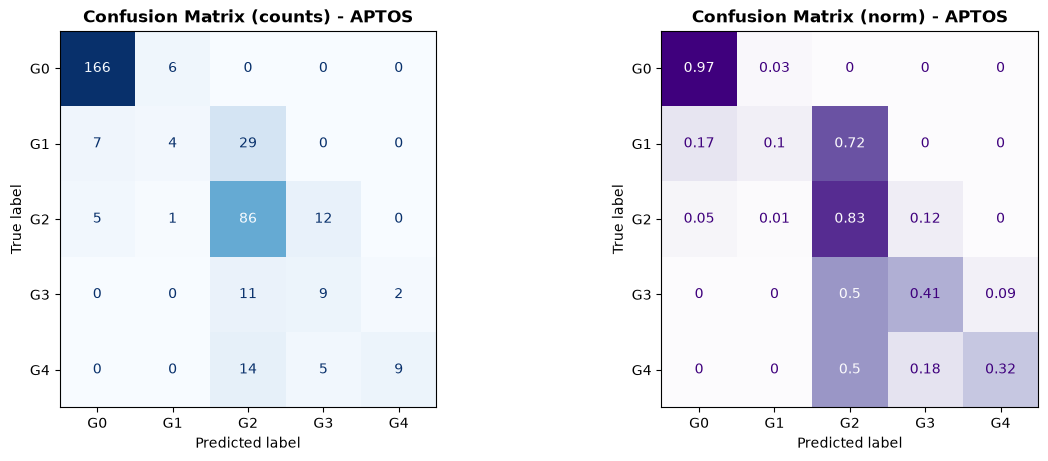

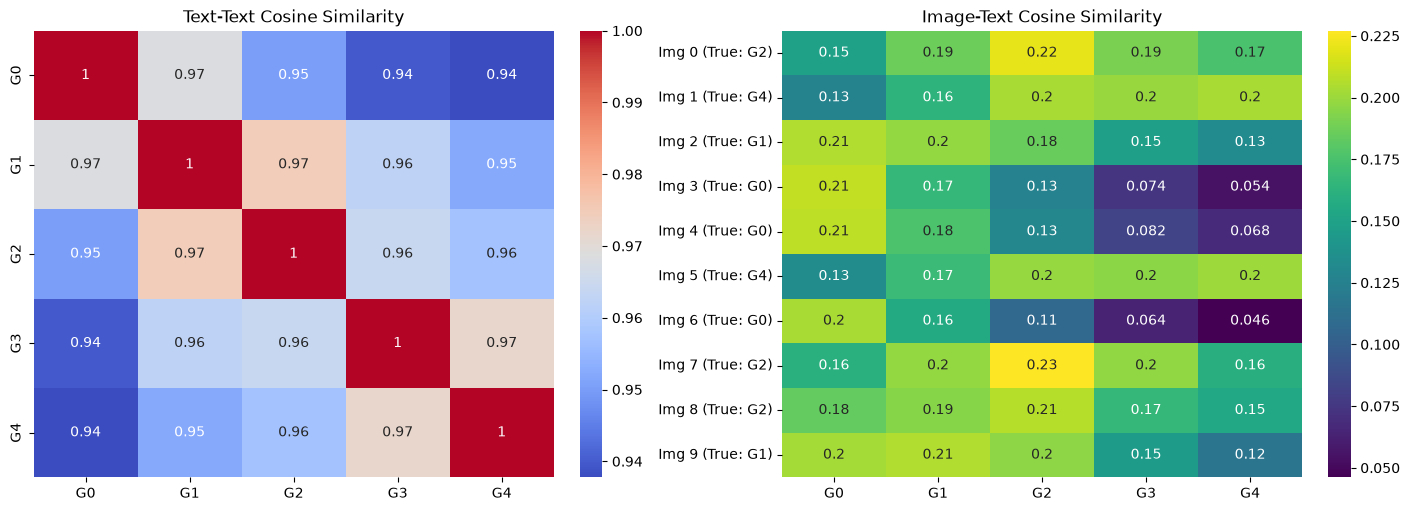

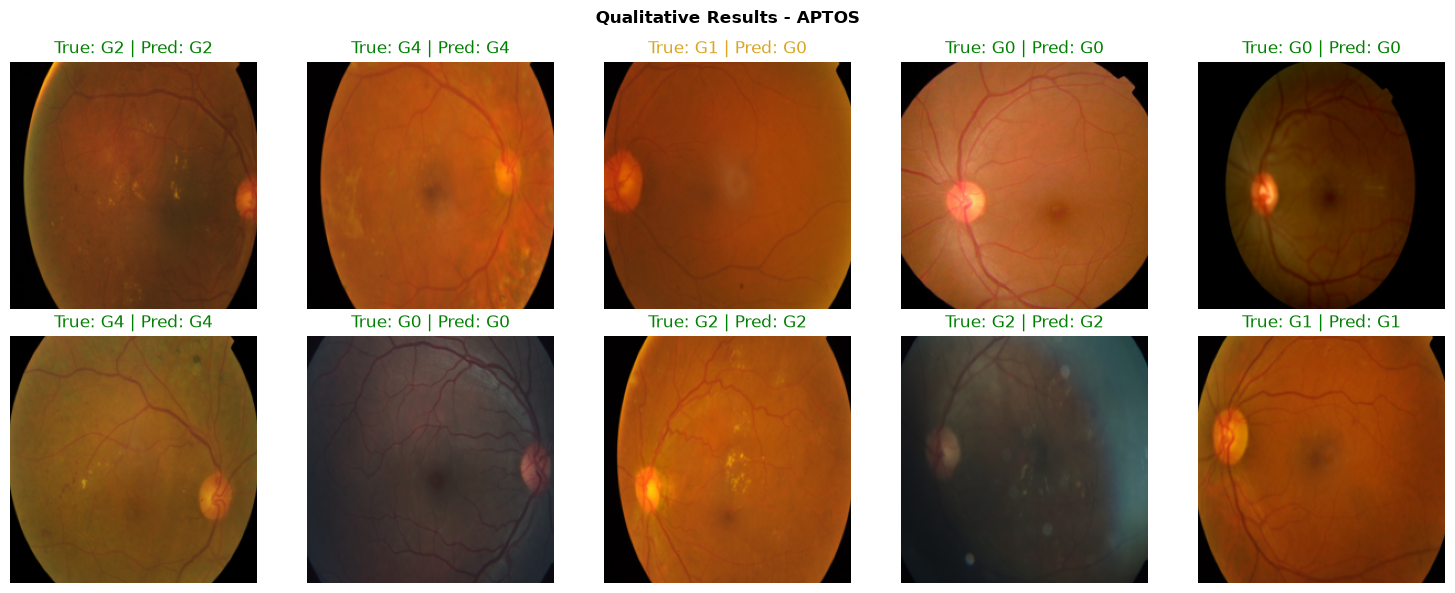

In [14]:
plot_model_analysis(aptos_model, aptos_data, 'APTOS')

## 3. Evaluate DeepDRiD Checkpoint

In [4]:
# Overwrite data paths for DeepDRiD
cfg.data_cfg.test_data_file = DEEPDR_TEST_TXT
cfg.data_cfg.val_data_file = DEEPDR_TEST_TXT
cfg.data_cfg.train_data_file = DEEPDR_TEST_TXT

# Setup runner checkpoint
deepdr_ckpt = str(CLIP_DR_PATH / "DEEPDR.ckpt")
runner_cfg.ckpt_path = deepdr_ckpt

# Initialize Model and Data
deepdr_model = Runner.load_from_checkpoint(deepdr_ckpt, **OmegaConf.to_container(runner_cfg))
deepdr_data = RegressionDataModule(**OmegaConf.to_container(cfg.data_cfg))

print("Testing DeepDRiD...")
trainer.test(model=deepdr_model, datamodule=deepdr_data)

Lightning automatically upgraded your loaded checkpoint from v1.9.4 to v2.6.5. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\CLIP-DR\DEEPDR.ckpt`
2026-08-09 12:36:34,012 - clipdr.utils.registry - INFO - Build obj: CLIPDR
2026-08-09 12:36:34,013 - clipdr.models.CLIPDR - INFO - Building CLIP model...
2026-08-09 12:36:34,015 - clipdr.models.CLIPDR - INFO - Text backbone : RN50's counterpart.
2026-08-09 12:36:36,042 - clipdr.models.CLIPDR - INFO - Image backbone: RN50
2026-08-09 12:36:36,043 - clipdr.models.CLIPDR - INFO - CLIP Image encoder: RN50!
2026-08-09 12:36:36,164 - clipdr.models.CLIPDR - INFO - convert `clip_model` to float32. if need fp16 model, call `clip.model.convert_weights`
2026-08-09 12:36:36,166 - clipdr.utils.registry - INFO - Build obj: PlainPromptLearner
2026-08-09 12:36:36,167 - clipdr.models.prompt_leaners.plain_prompt_learner - INFO - init con

Testing DeepDRiD...


d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\core\module.py:522: You called `self.log('test_mae_exp_metric', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\core\module.py:522: You called `self.log('test_acc_exp_metric', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\core\module.py:522: You called `self.log('test_exp_DGDR_auc_metric', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\pytorch_lightning\core\module.py:522: You called `self.log('test_exp_DGDR_f1_metric', 

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃         Test metric         ┃        DataLoader 0         ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│     test_acc_exp_metric     │     0.45749998092651367     │
│     test_acc_max_metric     │     0.4624999761581421      │
│  test_exp_DGDR_auc_metric   │     0.7776406407356262      │
│   test_exp_DGDR_f1_metric   │      0.399517297744751      │
│ test_exp_roc_curves0_metric │      0.836726188659668      │
│ test_exp_roc_curves1_metric │        0.6787109375         │
│ test_exp_roc_curves2_metric │     0.7569531202316284      │
│ test_exp_roc_curves3_metric │     0.8667968511581421      │
│ test_exp_roc_curves4_metric │     0.7861111164093018      │
│     test_mae_exp_metric     │     0.7132356762886047      │
│     test_mae_max_metric     │     0.7049999833106995      │
│  test_max_DGDR_auc_metric   │     0.7776406407356262      │
│   test_max_DGDR_f1_metric   │     0.3917984664440155      │
│ test_max_roc_curves0_metric │      0.836726188659668      │
│ test_max_roc_curves1_metric │        0.6787109375         │
│ test_max_roc_curves2_metric │     0.7569531202316284      │
│ test_max_roc_curves3_metric │     0.8667968511581421      │
│ test_max_roc_curves4_metric │     0.7861111164093018      │
└─────────────────────────────┴─────────────────────────────┘

[{'test_mae_exp_metric': 0.7132356762886047,
  'test_acc_exp_metric': 0.45749998092651367,
  'test_exp_DGDR_auc_metric': 0.7776406407356262,
  'test_exp_DGDR_f1_metric': 0.399517297744751,
  'test_exp_roc_curves0_metric': 0.836726188659668,
  'test_exp_roc_curves1_metric': 0.6787109375,
  'test_exp_roc_curves2_metric': 0.7569531202316284,
  'test_exp_roc_curves3_metric': 0.8667968511581421,
  'test_exp_roc_curves4_metric': 0.7861111164093018,
  'test_mae_max_metric': 0.7049999833106995,
  'test_acc_max_metric': 0.4624999761581421,
  'test_max_DGDR_auc_metric': 0.7776406407356262,
  'test_max_DGDR_f1_metric': 0.3917984664440155,
  'test_max_roc_curves0_metric': 0.836726188659668,
  'test_max_roc_curves1_metric': 0.6787109375,
  'test_max_roc_curves2_metric': 0.7569531202316284,
  'test_max_roc_curves3_metric': 0.8667968511581421,
  'test_max_roc_curves4_metric': 0.7861111164093018}]

--- Analyzing DeepDRiD ---


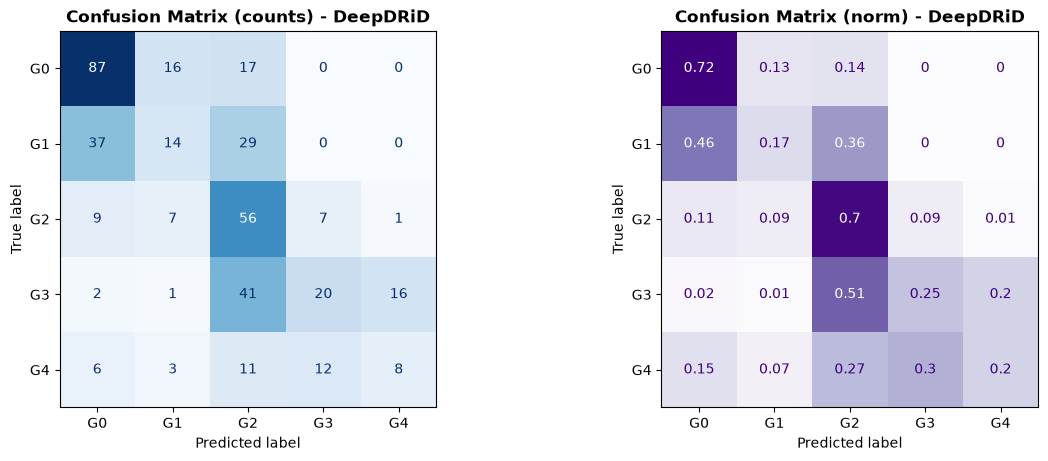

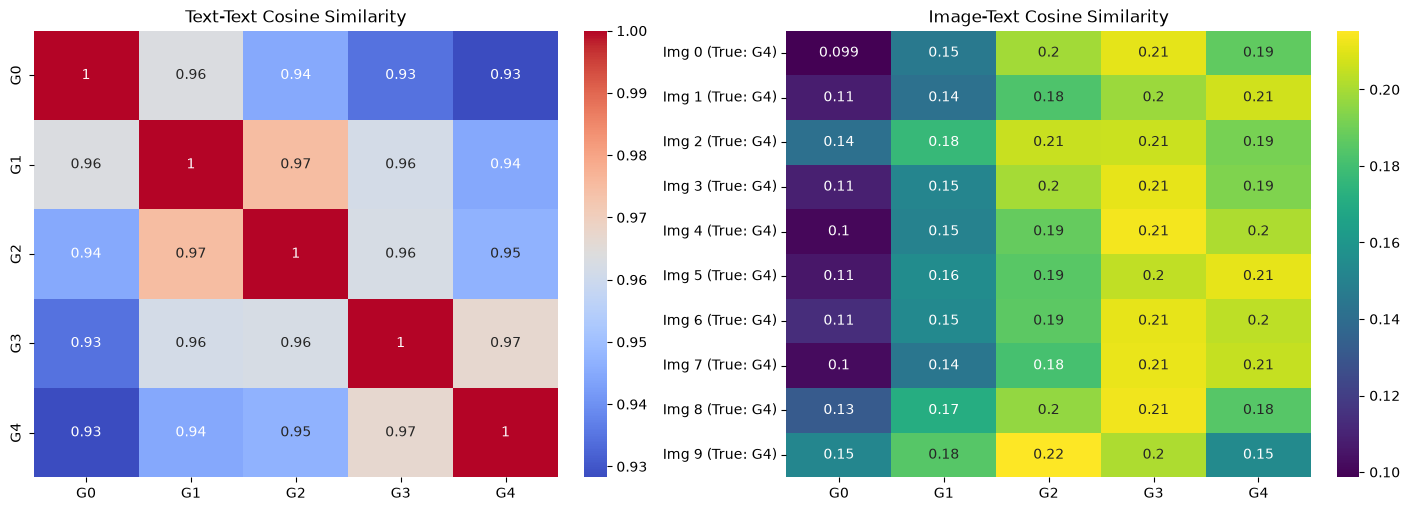

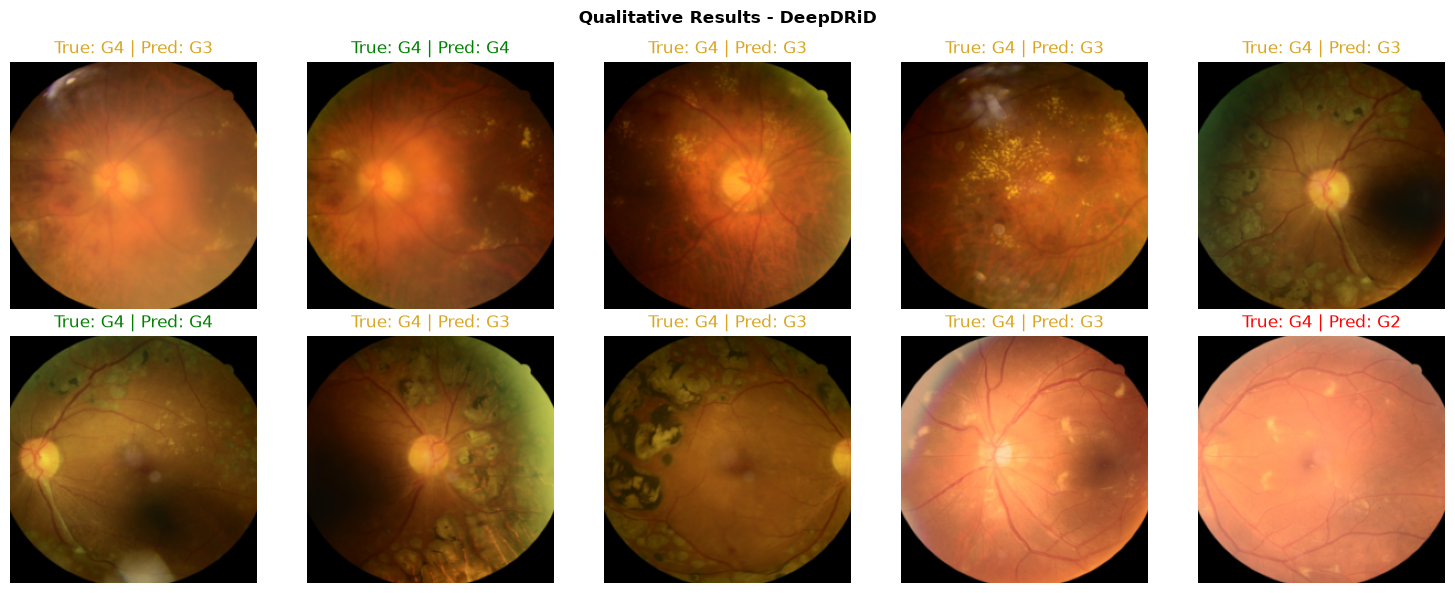

In [15]:
plot_model_analysis(deepdr_model, deepdr_data, 'DeepDRiD')
